# Model Comparison, Forecast and Capacity Plan

**Goal:** find a good forecast for the next 2 hours, show it beats simple guesses, and turn it into a capacity rule.
Each section has: **Question → What I did → What I found → Decision**.

**Rule:** I choose the model using only the training window (first 110 points). The holdout (last 24 points) is only used in the very last section, once, after the model and margin were already chosen.

**Targets:**
- `active_vm_count`: how many VMs are running
- `aggregate_cpu_utilization`: the average CPU % over all VMs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from forecasting.data import load, build_targets, split, HORIZON
from forecasting.models import BASELINES, STATISTICAL, FALLBACKS
from forecasting.validate import compare, rolling_origin

sns.set_theme(style="whitegrid")

cpu, meta = load("../challenge_data")
targets = build_targets(cpu)                    # build both target series from ALL data first
train, holdout_times = split(targets, HORIZON)  # then split: first 110 = train, last 24 = holdout (times only)

ALL_MODELS = {**BASELINES, **STATISTICAL}
cpu_values = train["aggregate_cpu_utilization"].to_numpy()    # training values only
count_values = train["active_vm_count"].to_numpy()

print("training points:", len(train), "| last training timestamp:", train.index[-1])   # expect 110 and 32700
print("models to compare:", list(ALL_MODELS))

training points: 110 | last training timestamp: 32700
models to compare: ['persistence', 'ma6', 'ma12', 'train_mean', 'drift', 'ar1', 'ar2', 'arma11', 'arima111', 'ima11', 'ets_ses', 'ets_damped', 'sarima_s12', 'ridge12']


## 1. How do I test a forecast fairly?
**Question:** How can I know a model is good *before* I see the real future?
**What I did:** Used **rolling-origin validation**. I pretend the forecast starts at an earlier time (the "origin"), train only on data before it, forecast 24 steps, and compare with what really happened. Then I move the origin forward and repeat.

**Why this is fair:**
- The model never sees data after its origin, so there is no leakage.
- It copies the real situation: forecast the next 2 hours from everything known so far.
- Several origins give several tests, not just one lucky or unlucky one.

I never shuffle the data, because shuffling would let the model peek at the future.

**Scores I use:**
- **MAE:** the average size of the error, in CPU percentage points
- **RMSE:** like MAE, but big mistakes count more
- **Improvement over persistence:** how much better than "the future equals the last value"

## 2. Which model forecasts CPU best?
**Question:** Does any model beat the simple guesses?
**What I did:** Ran every model through rolling-origin validation and ranked them by average MAE (lower is better).

                mae    rmse    mase
arma11       0.1908  0.2322  1.5214
ar2          0.1912  0.2314  1.5258
ridge12      0.1967  0.2378  1.5706
ar1          0.1974  0.2370  1.5758
train_mean   0.2059  0.2455  1.6438
arima111     0.2227  0.2665  1.7762
ima11        0.2232  0.2669  1.7799
ets_ses      0.2232  0.2670  1.7800
ma6          0.2369  0.2820  1.8890
ets_damped   0.2425  0.2877  1.9341
ma12         0.2432  0.2846  1.9396
persistence  0.2516  0.2885  2.0042
drift        0.2829  0.3212  2.2537
sarima_s12   0.3114  0.3577  2.4940

models that silently fell back to the mean: 0

improvement over persistence (%):
arma11         24.2
ar2            24.0
ridge12        21.8
ar1            21.5
train_mean     18.2
arima111       11.5
ima11          11.3
ets_ses        11.3
ma6             5.9
ets_damped      3.7
ma12            3.3
persistence     0.0
drift         -12.4
sarima_s12    -23.7
Name: mae, dtype: float64


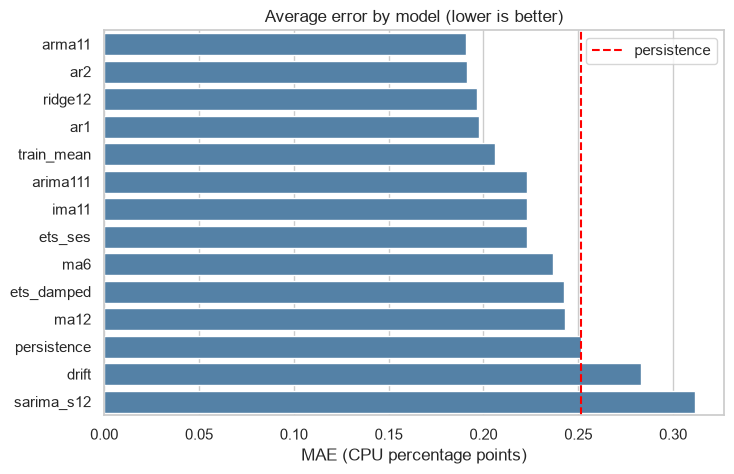

In [10]:
cpu_results = compare(cpu_values, ALL_MODELS, HORIZON)        # one row per model, sorted by MAE
print(cpu_results.round(4))
print()
print("models that silently fell back to the mean:", FALLBACKS["n"])   # should be 0

persistence_mae = cpu_results.loc["persistence", "mae"]
improvement = (1 - cpu_results["mae"] / persistence_mae) * 100
print()
print("improvement over persistence (%):")
print(improvement.round(1))

plt.figure(figsize=(8, 5))
sns.barplot(x=cpu_results["mae"], y=cpu_results.index, color="steelblue")
plt.axvline(persistence_mae, color="red", linestyle="--", label="persistence")
plt.legend()
plt.title("Average error by model (lower is better)")
plt.xlabel("MAE (CPU percentage points)")
plt.ylabel("")
plt.savefig("../reports/figures/10_model_mae.png", dpi=150, bbox_inches="tight")
plt.show()

**Found:** Models that pull back toward the average did best. ARMA(1,1) and AR(2) had the lowest MAE (about 0.19) and beat persistence by about 24%. Ridge and AR(1) were close behind (about 22%). The plain training mean was 18% better than persistence, so a flat level is already a strong forecast. Persistence (MAE 0.25) was near the bottom, drift was worse than persistence, and the seasonal model (SARIMA, s=12) was the worst, about 24% worse than persistence.

**Why:** The series is a stable level plus noise, so copying the last noisy value is a poor forecast, and extrapolating a trend (drift) makes it worse. With only about 9 hours of training data, a seasonal model adds noise and no signal.

**Decision:** The top four models are within about 0.01 MAE of each other, which is too close to call. I pick the best by the rule fixed in advance (lowest mean MAE, ties go to persistence), which selects ARMA(1,1). I do not claim it is truly better than AR(1) or AR(2).

## 3. What about the VM count?
**Question:** Which model forecasts `active_vm_count`?

In [3]:
count_results = compare(count_values, ALL_MODELS, HORIZON)
print(count_results.round(4))
print()
print("min / max count in training:", count_values.min(), "/", count_values.max())

             mae  rmse  mase
persistence  0.0   0.0   NaN
ma6          0.0   0.0   NaN
ma12         0.0   0.0   NaN
train_mean   0.0   0.0   NaN
drift        0.0   0.0   NaN
ar1          0.0   0.0   NaN
ar2          0.0   0.0   NaN
arma11       0.0   0.0   NaN
arima111     0.0   0.0   NaN
ima11        0.0   0.0   NaN
ets_ses      0.0   0.0   NaN
ets_damped   0.0   0.0   NaN
sarima_s12   0.0   0.0   NaN
ridge12      0.0   0.0   NaN

min / max count in training: 10000.0 / 10000.0


**Found:** The count is 10,000 at every time, so every model has an error of zero.
**Decision:** With a tie, I take the simplest model, persistence. This is a feature of this dataset (it only keeps VMs alive for the whole window), not a general result.

## 4. Is the ranking stable?
**Question:** Does the same model win at every origin, or was one origin lucky?
**What I did:** Plotted the error at each origin for a few models.

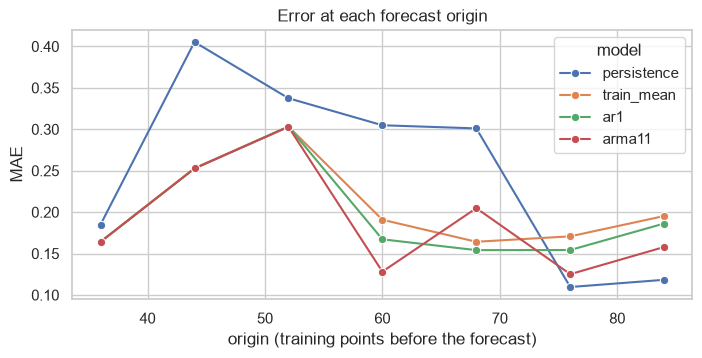

origins where each model has the lowest error:
arma11         3
persistence    2
train_mean     1
ar1            1
Name: count, dtype: int64


In [4]:
show = ["persistence", "train_mean", "ar1", "arma11"]
rows = []
for name in show:
    one = rolling_origin(cpu_values, ALL_MODELS[name], HORIZON)    # one row per origin
    one["model"] = name
    rows.append(one)
by_origin = pd.concat(rows)

plt.figure(figsize=(8, 3.5))
sns.lineplot(data=by_origin, x="origin", y="mae", hue="model", marker="o")
plt.title("Error at each forecast origin")
plt.xlabel("origin (training points before the forecast)"); plt.ylabel("MAE")
plt.savefig("../reports/figures/11_error_by_origin.png", dpi=150, bbox_inches="tight")
plt.show()

wins = by_origin.pivot(index="origin", columns="model", values="mae")
print("origins where each model has the lowest error:")
print(wins.idxmin(axis=1).value_counts())

**Found:** Across the 7 forecast origins, ARMA(1,1) had the lowest error at 3, persistence at 2, and the training mean and AR(1) at 1 each. No model wins everywhere. ARMA(1,1) wins most often, but persistence still wins 2 of 7 even though it is worse on average.

**Why:** The series is mostly a stable level with noise, so which model wins at a given origin depends on where the last point happened to land. When the last point is close to the average, persistence does fine. When it is far from the average, models that pull back to the mean do much better, and they win by more. That is why they come out ahead on average. The origins also overlap (24-step windows starting 8 steps apart), so these 7 tests are not independent.

**Decision:** The advantage of ARMA(1,1) over persistence is real on average (about 24%) but not consistent, so I report the average together with the spread, I call the top models a tie, and I do not claim ARMA(1,1) always wins.

## 5. Where does the forecast fail?
**Question:** Is the error the same for every step ahead, or does it grow?
**What I did:** Collected the error at each step ahead (1 = next 5 minutes, 24 = 2 hours ahead) over many origins and compared persistence with the best model.

selected model for CPU: arma11


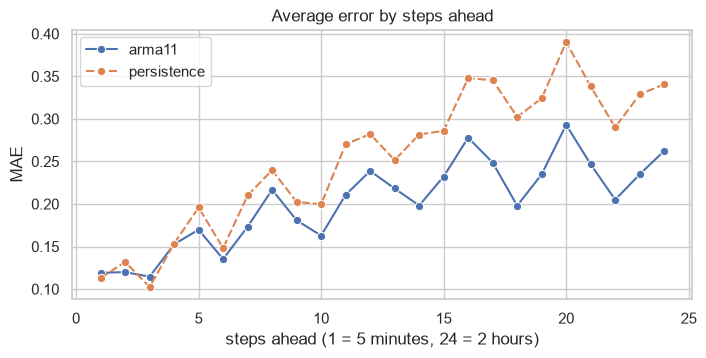

error at step 1 / 12 / 24:
      arma11  persistence
step                     
1      0.119        0.113
12     0.239        0.282
24     0.262        0.341


In [5]:
def collect_errors(values, model, h=24, step=4, min_train=36):
    # Returns one row per (origin, step ahead) with the error = actual - forecast
    rows = []
    for origin in range(min_train, len(values) - h + 1, step):
        forecast = model(values[:origin], h)       # uses only data before the origin
        actual = values[origin:origin + h]
        for k in range(h):
            rows.append({"origin": origin, "step": k + 1,
                         "forecast": forecast[k], "actual": actual[k],
                         "error": actual[k] - forecast[k]})
    return pd.DataFrame(rows)

# the model my selection rule picks (lowest mean MAE, ties go to persistence)
tied = np.allclose(cpu_results["mae"], cpu_results["mae"].iloc[0], atol=1e-9)
best_name = "persistence" if tied else cpu_results.index[0]
best_model = ALL_MODELS[best_name]
print("selected model for CPU:", best_name)

best_errors = collect_errors(cpu_values, best_model)
persist_errors = collect_errors(cpu_values, ALL_MODELS["persistence"])

by_step = pd.DataFrame({
    best_name: best_errors["error"].abs().groupby(best_errors["step"]).mean(),
    "persistence": persist_errors["error"].abs().groupby(persist_errors["step"]).mean(),
})

plt.figure(figsize=(8, 3.5))
sns.lineplot(data=by_step, marker="o")
plt.title("Average error by steps ahead")
plt.xlabel("steps ahead (1 = 5 minutes, 24 = 2 hours)"); plt.ylabel("MAE")
plt.savefig("../reports/figures/12_error_by_step.png", dpi=150, bbox_inches="tight")
plt.show()

print("error at step 1 / 12 / 24:")
print(by_step.loc[[1, 12, 24]].round(3))

**Found:** Error grows with the forecast horizon for both models. For ARMA(1,1) it roughly doubles, from about 0.12 at 5 minutes ahead to about 0.26 at 2 hours ahead. In the first 3 steps persistence is as good as ARMA(1,1) (0.113 vs 0.119 at step 1). From about step 4 onward ARMA(1,1) is better, and the gap widens: at step 12 it is about 15% lower (0.239 vs 0.282), and at step 24 about 23% lower (0.262 vs 0.341).

**Why:** Over the next 5 to 15 minutes the series barely moves, so the last value is already a good forecast. Over longer horizons the last noisy value drifts away from where the series settles, and a model that pulls back toward the average does better. The lines are jagged because they come from only 13 overlapping origins.

**Decision:** The model's benefit is at the 1 to 2 hour planning horizon, which is the horizon of this task. For very short-term use, the last value is enough. Even at 2 hours ahead the error (0.26 points) is under 3% of the 9.4% level, so the forecast is accurate in relative terms.

## 6. The final forecast
**Question:** What does the forecast look like next to the history?
**What I did:** Read `predictions.csv` (created by `python -m forecasting.predict`) and plotted it after the last training points.

     timestamp  active_vm_count  aggregate_cpu_utilization
min    33000.0          10000.0                      9.195
max    39900.0          10000.0                      9.340


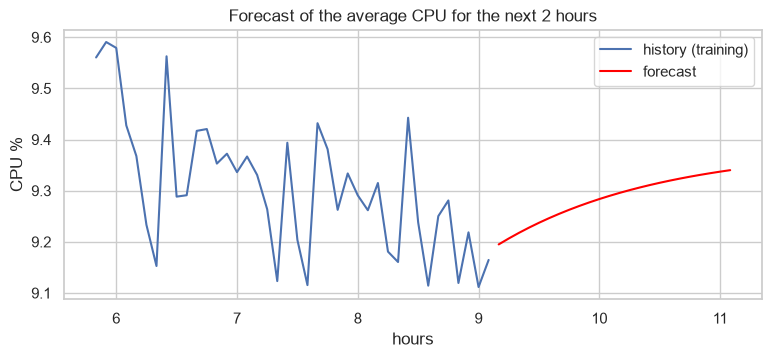

In [6]:
pred = pd.read_csv("../predictions.csv")
assert list(pred["timestamp"]) == list(holdout_times), "prediction timestamps do not match"
print(pred.describe().loc[["min", "max"]].round(3))

recent = train["aggregate_cpu_utilization"].iloc[-40:]          # last 40 training points
plt.figure(figsize=(9, 3.5))
plt.plot(recent.index / 3600, recent.values, label="history (training)")
plt.plot(pred["timestamp"] / 3600, pred["aggregate_cpu_utilization"], color="red", label="forecast")
plt.title("Forecast of the average CPU for the next 2 hours")
plt.xlabel("hours"); plt.ylabel("CPU %"); plt.legend()
plt.savefig("../reports/figures/13_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

**Found:** The forecast starts just above the last training value (about 9.2%) and rises smoothly to about 9.34% by the end of the 2 hours. That is back toward the training average (about 9.4%) but not all the way there. It is a smooth curve with none of the jagged ups and downs of the history.

**Why:** The model has learned that the series pulls back toward its average, so the forecast climbs toward it from the low recent level. It has no way to predict the random 5-minute noise or future spikes, so it forecasts only the expected level.

## 7. How wrong can the forecast be? (the safety margin)
**Question:** How much extra capacity should I add on top of the forecast?
**What I did:** Used the errors from rolling-origin validation (training data only). The error is `actual - forecast`. A positive error means the real value was higher than forecast, which is the risky direction. For each margin I measured how often the real value goes above forecast + margin.

 target_coverage  margin_points  margin_percent_of_level  share_above_band  avg_overshoot_when_above  avg_unused_headroom
            0.50         -0.035                     -0.4             0.500                     0.255                0.143
            0.80          0.275                      2.9             0.202                     0.142                0.354
            0.90          0.428                      4.5             0.103                     0.052                0.460
            0.95          0.468                      5.0             0.051                     0.043                0.474


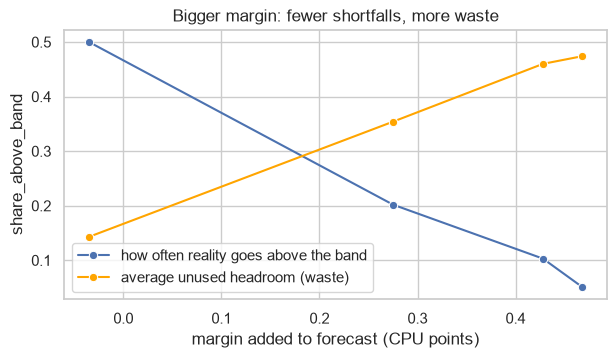


chosen margin (90% band): 0.428 CPU points


In [7]:
errors = best_errors["error"]
forecast_level = cpu_values.mean()

rows = []
for q in [0.5, 0.8, 0.9, 0.95]:
    margin = errors.quantile(q)                        # the margin that covers a share q of past errors
    short = errors[errors > margin] - margin           # how far reality went above forecast + margin
    rows.append({
        "target_coverage": q,
        "margin_points": round(margin, 3),
        "margin_percent_of_level": round(margin / forecast_level * 100, 1),
        "share_above_band": round((errors > margin).mean(), 3),
        "avg_overshoot_when_above": round(short.mean(), 3) if len(short) else 0.0,
        "avg_unused_headroom": round((margin - errors[errors <= margin]).mean(), 3),
    })
margin_table = pd.DataFrame(rows)
print(margin_table.to_string(index=False))

plt.figure(figsize=(7, 3.5))
sns.lineplot(data=margin_table, x="margin_points", y="share_above_band", marker="o", label="how often reality goes above the band")
sns.lineplot(data=margin_table, x="margin_points", y="avg_unused_headroom", marker="o", color="orange", label="average unused headroom (waste)")
plt.title("Bigger margin: fewer shortfalls, more waste")
plt.xlabel("margin added to forecast (CPU points)")
plt.savefig("../reports/figures/14_margin_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

MARGIN = errors.quantile(0.9)     # my choice: cover about 90% of past errors
print()
print("chosen margin (90% band):", round(MARGIN, 3), "CPU points")

**Found:** A bigger margin means reality goes above the band less often, but more headroom sits unused. With no margin (the 50% row), reality is above the forecast half the time. With the 80% band (margin 0.28 points, 2.9% of the level) it is above about 20% of the time. With the 90% band (margin 0.43 points, 4.5% of the level) it is above about 10% of the time, and when it is, it only overshoots by about 0.05 points. The unused headroom rises from 0.14 to 0.35 to 0.46 points across those bands. Going from the 90% to the 95% band adds only 0.04 points of margin, halves the shortfall rate from about 10% to about 5%, and adds only 0.014 points of waste.

**Why:** This is the trade-off between under-provisioning and over-provisioning.
- **Under-provisioning:** too little capacity, so VMs are throttled, users see slow service, and SLAs can be broken.

- **Over-provisioning:** too much capacity, so money is wasted on machines that sit idle.
The margins are small compared with the 9.4% level because the average of 10,000 VMs is smooth and the forecast errors are small.

**Decision:** I chose the 90% band, fixed before I looked at the holdout. A team that cares more about outages than cost could take the 95% band, which costs very little extra margin here. A team that cares more about cost could take the 80% band. These margins come from about 13 overlapping windows, so the top 5% of errors is only a handful of values. The 95% figure in particular is a rough estimate.

## 8. The capacity rule
**Question:** What simple policy should an infrastructure team follow?
**What I did:** Combined the forecast band with the hot-VM findings from the EDA. The hot-VM numbers use only the training window.

In [8]:
tr = cpu[cpu["timestamp"].isin(train.index)]

# share of VMs above 80% CPU at each timestamp (training only)
share_above_80 = (tr["avg_cpu"] > 80).groupby(tr["timestamp"]).mean() * 100
TRIGGER = share_above_80.quantile(0.99)                 # alert level: higher than 99% of training timestamps

# VMs that are above 80% in more than half of the intervals = persistently hot
hot_fraction = (tr["avg_cpu"] > 80).groupby(tr["vm_id"]).mean()
persistent_hot = hot_fraction[hot_fraction > 0.5].index

next_forecast = pred["aggregate_cpu_utilization"].max()
upper_band = next_forecast + MARGIN

print("Rule 1 - fleet headroom")
print("  forecast for the next 2 hours (max):", round(next_forecast, 2), "%")
print("  plan capacity for the upper band    :", round(upper_band, 2), "%  (forecast + margin)")
print("  that is", round(MARGIN / next_forecast * 100, 1), "% above the forecast")
print()
print("Rule 2 - spike alert")
print("  normal share of VMs above 80%:", round(share_above_80.mean(), 2), "%")
print("  alert if it goes above        :", round(TRIGGER, 2), "%")
print()
print("Rule 3 - persistently hot VMs")
print("  VMs above 80% in more than half the intervals:", len(persistent_hot))
print("  as a share of the fleet:", round(len(persistent_hot) / tr['vm_id'].nunique() * 100, 2), "%")

Rule 1 - fleet headroom
  forecast for the next 2 hours (max): 9.34 %
  plan capacity for the upper band    : 9.77 %  (forecast + margin)
  that is 4.6 % above the forecast

Rule 2 - spike alert
  normal share of VMs above 80%: 1.27 %
  alert if it goes above        : 1.43 %

Rule 3 - persistently hot VMs
  VMs above 80% in more than half the intervals: 113
  as a share of the fleet: 1.13 %


**Found:** The forecast for the next 2 hours peaks at 9.34% average CPU. Adding the 90% safety margin gives an upper band of 9.77%, which is 4.6% more load than the forecast. Normally about 1.27% of VMs are above 80% CPU, and I set the spike alert at 1.43%, which is higher than 99% of training timestamps. In total, 113 VMs (1.13% of the fleet) were above 80% in more than half of the intervals.

**Units:** The margin is in CPU percentage points of the fleet average, not in cores or servers, because the data has no capacity numbers. In practice, it means capacity should cover about 4.6% more load than the forecast.

**Limitations of the rules:**
- The spike alert is narrow. The share of VMs above 80% normally moves between about 1.1% and 1.45%, so the alert level (1.43%) sits very close to normal. It was set from only 110 points, so treat it as a starting value to tune, not a tested threshold.
- In the EDA, the share above 80% stayed flat during the peak, while the share above 50% rose. So this alert would not have caught that peak. Tracking the share above 50% as well would be a sensible next step.
- All three rules come from the training window only and have not been tested on a longer history.

## 9. Final check on the holdout (run once)
**Question:** Does what I chose hold up on the 2 hours I never touched?
**What I did:** Only now did I read the real values of the last 24 points. The model and margin were already fixed. I do not change anything after this cell.

model        MAE: 0.0992 | RMSE: 0.1232
persistence  MAE: 0.1468 | RMSE: 0.1848
improvement over persistence (MAE): 32.4 %

holdout points above the upper band: 0 of 24
average unused headroom: 0.443 CPU points


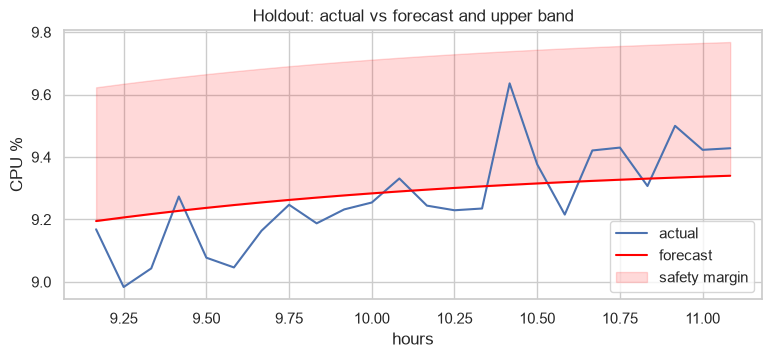

In [9]:
actual = targets.loc[holdout_times, "aggregate_cpu_utilization"].to_numpy()
forecast = pred["aggregate_cpu_utilization"].to_numpy()
persist_forecast = ALL_MODELS["persistence"](cpu_values, len(actual))

def mae(a, f):  return float(np.mean(np.abs(a - f)))
def rmse(a, f): return float(np.sqrt(np.mean((a - f) ** 2)))

print("model        MAE:", round(mae(actual, forecast), 4), "| RMSE:", round(rmse(actual, forecast), 4))
print("persistence  MAE:", round(mae(actual, persist_forecast), 4), "| RMSE:", round(rmse(actual, persist_forecast), 4))
print("improvement over persistence (MAE):", round((1 - mae(actual, forecast) / mae(actual, persist_forecast)) * 100, 1), "%")

upper = forecast + MARGIN
print()
print("holdout points above the upper band:", int((actual > upper).sum()), "of", len(actual))
print("average unused headroom:", round(float(np.mean(upper - actual)), 3), "CPU points")

plt.figure(figsize=(9, 3.5))
plt.plot(holdout_times / 3600, actual, label="actual")
plt.plot(holdout_times / 3600, forecast, color="red", label="forecast")
plt.fill_between(holdout_times / 3600, forecast, upper, color="red", alpha=0.15, label="safety margin")
plt.title("Holdout: actual vs forecast and upper band")
plt.xlabel("hours"); plt.ylabel("CPU %"); plt.legend()
plt.savefig("../reports/figures/15_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

**Found:** On the holdout, the model had an MAE of 0.099 and an RMSE of 0.123, against 0.147 and 0.185 for persistence. That is about 32% better on MAE. None of the 24 real values went above the upper band (forecast plus the 90% margin). The highest real value was about 9.64%, against a band of about 9.74%. The average unused headroom was 0.44 CPU points, about 4.7% of the level, which is almost the whole margin.

**What the plot shows:** The real values started below the forecast, then rose above it in the second hour, with one spike near hour 10.4. The forecast is a smooth curve and cannot follow these ups and downs, but the band absorbed all of them.

**Be careful:**
- This is 24 strongly linked points, so it is one test, not 24 independent ones. The rolling-origin result (about 24% better than persistence) is the stronger evidence. The holdout error (0.099) is also about half of the average validation error (0.19), so this window was easier than average, which is part of why 32% is higher than 24%.
- A 90% band should miss about 10% of the time, so 0 of 24 is consistent with it, but it also means the margin was generous for this window (the average unused headroom was 0.44 points). One window cannot tell me whether the margin is too large.
- I made no changes after seeing this result.

## 10. Summary and limitations

**What I did:**
- Built the two target series and split by time (110 train, 24 holdout).
- Compared simple baselines with ARIMA, ETS and ridge using rolling-origin validation.
- Chose the model with a rule fixed in advance: lowest mean MAE, ties go to persistence.
- Scored the holdout once, after everything was decided.
- Turned the forecast errors into a safety margin and a three-part capacity rule.

**What I found:**
- The VM count never changes in this data, so persistence is exact.
- Average CPU is smooth and returns to its average, so models that pull back to the average beat persistence.
- The top models are close, so the choice among them is not strong evidence.
- The real risk is in spikes and in a small group of hot VMs, not in the average.

**Limitations:**
- Only about 9 hours of training data (11 in total), so I cannot learn daily cycles.
- The VM count has no variation by construction (only VMs alive for the whole window are included), so this does not show real churn.
- The safety margin comes from a few overlapping windows and is a rough estimate.
- The holdout is one short window, so it is a noisy test.

**With more time:**
- Longer history, so daily and weekly patterns can be modelled.
- Forecast per VM category and add up the results, and check if it helps.
- Proper prediction intervals, and a forecast of the share of hot VMs, not only the average.